[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Original Paragraph:
Artificial Intelligence is changing the way people interact with technology. It helps computers learn from data and solve complex problems. AI is used in healthcare, education, transportation and entertainment. Smart assistants can understand questions and provide useful answers. I find Artificial Intelligence interesting because it makes everyday tasks easier and creates new opportunities for innovation.

Cleaned Text:
artificial intelligence is changing the way people interact with technology it helps computers learn from data and solve complex problems ai is used in healthcare education transportation and entertainment smart assistants can understand questions and provide useful answers i find artificial intelligence interesting because it makes everyday tasks easier and creates new opportunities for innovation

Word Tokens:
['artificial', 'intelligence', 'is', 'changing', 'the', 'way', 'people', 'interact', 'with', 'technology', 'it', 'helps', 'computers', 'lear

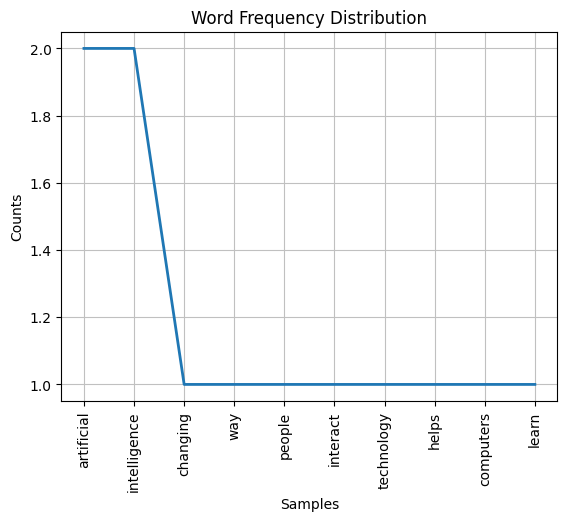

In [1]:
import re
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

paragraph = """Artificial Intelligence is changing the way people interact with technology. It helps computers learn from data and solve complex problems. AI is used in healthcare, education, transportation and entertainment. Smart assistants can understand questions and provide useful answers. I find Artificial Intelligence interesting because it makes everyday tasks easier and creates new opportunities for innovation."""

clean_text = re.sub(r'[^\w\s]', '', paragraph.lower())

words = word_tokenize(clean_text)
sentences = sent_tokenize(paragraph)

split_words = paragraph.split()
tokenized_words = word_tokenize(paragraph)

print("Original Paragraph:")
print(paragraph)

print("\nCleaned Text:")
print(clean_text)

print("\nWord Tokens:")
print(words)

print("\nSentences:")
print(sentences)

print("\nUsing split():")
print(split_words)

print("\nUsing word_tokenize():")
print(tokenized_words)

print("\nStopword Removal:")
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
print(filtered_words)

freq = FreqDist(filtered_words)

print("\nWord Frequency:")
print(freq.most_common())

freq.plot(10, title="Word Frequency Distribution")
plt.show()

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

clean_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in clean_words if word not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [stemmer.stem(word) for word in filtered_words]
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]

print("Original Words:")
print(filtered_words)

print("\nStemmed Words:")
print(stemmed_words)

print("\nLemmatized Words:")
print(lemmatized_words)

print("\nComparison:")
for word, stem, lemma in zip(filtered_words, stemmed_words, lemmatized_words):
    print(word, "->", stem, "->", lemma)

print("\nExplanation:")
print("Stemming removes word endings to produce a root-like form. Lemmatization converts words into their meaningful dictionary form. Stemming is faster and useful in basic text processing, while lemmatization is preferred when meaningful and grammatically correct words are important.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Original Words:
['artificial', 'intelligence', 'changing', 'way', 'people', 'interact', 'technology', 'helps', 'computers', 'learn', 'data', 'solve', 'complex', 'problems', 'ai', 'used', 'healthcare', 'education', 'transportation', 'entertainment', 'smart', 'assistants', 'understand', 'questions', 'provide', 'useful', 'answers', 'find', 'artificial', 'intelligence', 'interesting', 'makes', 'everyday', 'tasks', 'easier', 'creates', 'new', 'opportunities', 'innovation']

Stemmed Words:
['artifici', 'intellig', 'chang', 'way', 'peopl', 'interact', 'technolog', 'help', 'comput', 'learn', 'data', 'solv', 'complex', 'problem', 'ai', 'use', 'healthcar', 'educ', 'transport', 'entertain', 'smart', 'assist', 'understand', 'question', 'provid', 'use', 'answer', 'find', 'artifici', 'intellig', 'interest', 'make', 'everyday', 'task', 'easier', 'creat', 'new', 'opportun', 'innov']

Lemmatized Words:
['artificial', 'intelligence', 'changing', 'way', 'people', 'interact', 'technology', 'help', 'comput

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps computers learn and make decisions.",
    "Machine learning uses data to train intelligent computer systems.",
    "Blockchain provides secure and transparent digital transactions."
]

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words:")
print(bow_matrix.toarray())
print(count_vectorizer.get_feature_names_out())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

features = tfidf_vectorizer.get_feature_names_out()

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray()[0]
    top_indices = scores.argsort()[-3:][::-1]

    print("\nText", i + 1, ":", text)
    print("Top 3 Keywords:")

    for index in top_indices:
        print(features[index], ":", round(scores[index], 3))

Bag of Words:
[[1 1 0 0 1 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 1 0 0 0 0 1 0 1 1 0 0 0 1 1 1 0 0 1]
 [1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 1 1 0]]
['and' 'artificial' 'blockchain' 'computer' 'computers' 'data' 'decisions'
 'digital' 'helps' 'intelligence' 'intelligent' 'learn' 'learning'
 'machine' 'make' 'provides' 'secure' 'systems' 'to' 'train'
 'transactions' 'transparent' 'uses']

TF-IDF Matrix:
[[0.27626457 0.36325471 0.         0.         0.36325471 0.
  0.36325471 0.         0.36325471 0.36325471 0.         0.36325471
  0.         0.         0.36325471 0.         0.         0.
  0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.33333333 0.         0.33333333
  0.         0.         0.         0.         0.33333333 0.
  0.33333333 0.33333333 0.         0.         0.         0.33333333
  0.33333333 0.33333333 0.         0.         0.33333333]
 [0.29651988 0.         0.38988801 0.         0.         0.
  0.         0.389888

In [4]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.tokenize import word_tokenize

text1 = """Artificial Intelligence allows computers to learn from data.
It helps machines solve problems and make decisions.
AI is used in healthcare, education and transportation.
It can automate tasks and improve productivity.
Many industries use AI to develop smart applications."""

text2 = """Blockchain is a digital technology used to store information.
It maintains records in a secure and distributed manner.
Blockchain is commonly used in digital currencies.
It provides transparency and reduces data manipulation.
Many businesses use blockchain for secure transactions."""

clean1 = re.findall(r'\b[a-zA-Z]+\b', text1.lower())
clean2 = re.findall(r'\b[a-zA-Z]+\b', text2.lower())

print("Text 1 Tokens:")
print(clean1)

print("\nText 2 Tokens:")
print(clean2)

set1 = set(clean1)
set2 = set(clean2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("\nJaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine, 4))

print("\nAnalysis:")
print("Jaccard similarity compares the common unique words between two texts.")
print("Cosine similarity compares the TF-IDF vectors and considers the importance of words.")
print("Cosine similarity gives better insights here because it considers word importance rather than only checking whether words are common.")

Text 1 Tokens:
['artificial', 'intelligence', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'it', 'helps', 'machines', 'solve', 'problems', 'and', 'make', 'decisions', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'it', 'can', 'automate', 'tasks', 'and', 'improve', 'productivity', 'many', 'industries', 'use', 'ai', 'to', 'develop', 'smart', 'applications']

Text 2 Tokens:
['blockchain', 'is', 'a', 'digital', 'technology', 'used', 'to', 'store', 'information', 'it', 'maintains', 'records', 'in', 'a', 'secure', 'and', 'distributed', 'manner', 'blockchain', 'is', 'commonly', 'used', 'in', 'digital', 'currencies', 'it', 'provides', 'transparency', 'and', 'reduces', 'data', 'manipulation', 'many', 'businesses', 'use', 'blockchain', 'for', 'secure', 'transactions']

Jaccard Similarity: 0.1667
Cosine Similarity: 0.2513

Analysis:
Jaccard similarity compares the common unique words between two texts.
Cosine similarity compares the TF-IDF vectors and cons

Sentiment Analysis:

Review: This product is amazing and works perfectly. I really love it.
Polarity: 0.55
Subjectivity: 0.75
Sentiment: Positive

Review: The service was excellent and the staff was very helpful.
Polarity: 0.6
Subjectivity: 0.65
Sentiment: Positive

Review: The product is terrible and stopped working after two days.
Polarity: -1.0
Subjectivity: 1.0
Sentiment: Negative

Review: I am disappointed with the poor quality and slow service.
Polarity: -0.483
Subjectivity: 0.583
Sentiment: Negative

Review: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive

Review: The service was average and nothing special.
Polarity: 0.104
Subjectivity: 0.486
Sentiment: Positive



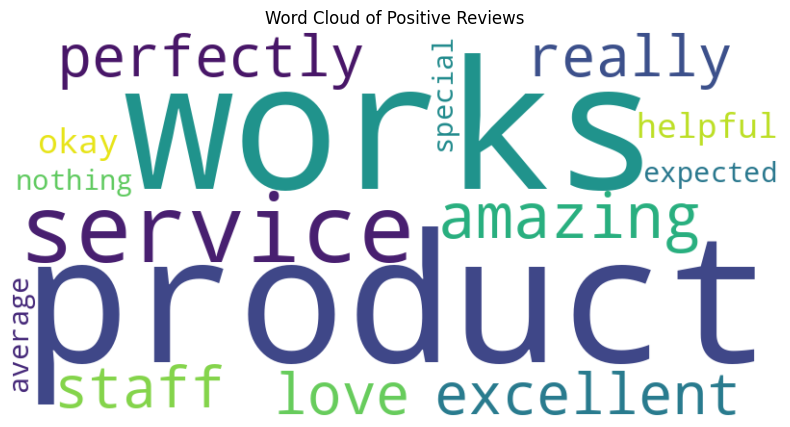

In [5]:
!pip -q install textblob wordcloud

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This product is amazing and works perfectly. I really love it.",
    "The service was excellent and the staff was very helpful.",
    "The product is terrible and stopped working after two days.",
    "I am disappointed with the poor quality and slow service.",
    "The product is okay and works as expected.",
    "The service was average and nothing special."
]

positive_reviews = []

print("Sentiment Analysis:\n")

for review in reviews:
    analysis = TextBlob(review)

    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)
    print()

if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white'
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title("Word Cloud of Positive Reviews")
    plt.show()

In [6]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_text = """Technology plays an important role in our daily lives. Computers help people perform tasks quickly and efficiently. Artificial intelligence allows machines to learn from information and make decisions. The internet connects people across the world and provides access to knowledge. Mobile applications make communication and entertainment easier. Technology is also used in education, healthcare and business. Students use digital tools to learn new skills and complete their assignments. Modern technology continues to develop and creates new opportunities. In the future, smart machines and digital systems will become even more useful. Technology helps society grow and makes many everyday activities easier."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1

sequences = []

for line in training_text.split('.'):
    line = line.strip()

    if line:
        token_list = tokenizer.texts_to_sequences([line])[0]

        for i in range(1, len(token_list)):
            sequences.append(token_list[:i + 1])

max_length = max(len(seq) for seq in sequences)

sequences = pad_sequences(
    sequences,
    maxlen=max_length,
    padding='pre'
)

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential([
    Embedding(total_words, 50, input_length=max_length - 1),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=100, verbose=1)

def generate_text(seed_word, next_words):
    result = seed_word

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]

        if not token_list:
            break

        token_list = pad_sequences(
            [token_list],
            maxlen=max_length - 1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_word = np.argmax(predicted, axis=1)[0]

        output_word = tokenizer.index_word.get(predicted_word, '')

        if not output_word:
            break

        result += " " + output_word

    return result

print("\nGenerated Text:\n")

print(generate_text("technology", 12))
print(generate_text("artificial", 12))
print(generate_text("computers", 12))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.0111 - loss: 4.3324  
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1111 - loss: 4.3229
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1000 - loss: 4.3149
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1000 - loss: 4.3049
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1000 - loss: 4.2910
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1000 - loss: 4.2713
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1000 - loss: 4.2303
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1000 - loss: 4.1566
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1000 - loss: 4.0961
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1000 - loss: 4.1031
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1000 - loss: 4.0664
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1000 - 